In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

sns.set_theme(style="whitegrid")
print("Setup OK, pandas version:", pd.__version__)

Setup OK, pandas version: 3.0.6


In [2]:
df = pd.read_csv("../data/life_expectancy.csv")
df_raw = df.copy()
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
df.shape

(2938, 22)

### Dataset Overview
The dataset contains **2,938 rows** and **22 columns**. Each row represents one country in one year, with columns for life expectancy, mortality, immunization coverage (Hepatitis B, Polio, Diphtheria), economic indicators (GDP, expenditure) and social indicators (schooling, income composition of resources).

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

### Data Types
`df.info()` shows that `Country` and `Status` are text columns, `Year`, `infant deaths`, `Measles` and `under-five deaths` are integers, and all other columns are `float64`. No numeric column is stored as text, so no type conversion is needed except for confirming `Year` as an integer.

Many columns have fewer non-null values than the 2,938 rows, which means they contain missing data. The column names are also inconsistent: some have leading or trailing spaces (for example ` BMI`, ` HIV/AIDS`, ` thinness  1-19 years`) and others contain spaces or special characters. These will be standardized before analysis.

In [5]:
(df.isnull().sum() / len(df) * 100).round(2).sort_values(ascending=False)

Population                         22.19
Hepatitis B                        18.82
GDP                                15.25
Total expenditure                   7.69
Alcohol                             6.60
Income composition of resources     5.68
Schooling                           5.55
 thinness  1-19 years               1.16
 thinness 5-9 years                 1.16
 BMI                                1.16
Diphtheria                          0.65
Polio                               0.65
Life expectancy                     0.34
Adult Mortality                     0.34
infant deaths                       0.00
Status                              0.00
Country                             0.00
Year                                0.00
under-five deaths                   0.00
Measles                             0.00
percentage expenditure              0.00
 HIV/AIDS                           0.00
dtype: float64

### Missing Values
The columns with the most missing data are:
- **Population** (22.19%, about 652 rows)
- **Hepatitis B** (18.82%, about 553 rows)
- **GDP** (15.25%, about 448 rows)

Moderate missingness appears in `Total expenditure` (7.69%), `Alcohol` (6.60%), `Income composition of resources` (5.68%) and `Schooling` (5.55%). `thinness 1-19 years`, `thinness 5-9 years` and `BMI` are missing about 1.16%, `Diphtheria` and `Polio` about 0.65%, and `Life expectancy` and `Adult Mortality` about 0.34% (10 rows each). The remaining columns have no missing values.

Because no column is missing more than about 22% of its values, dropping every incomplete row would discard a large part of the data. I will therefore handle each column according to its percentage and importance instead.

In [6]:
df.duplicated().sum()

np.int64(0)

### Duplicate Rows
No exact duplicate rows were found (`df.duplicated().sum()` returned 0), so no rows need to be removed for duplication.

### Summary of Initial Inspection
- The dataset has 2,938 rows and 22 columns covering multiple countries and years.
- Missing values are concentrated in `Population` (22.19%), `Hepatitis B` (18.82%) and `GDP` (15.25%), with smaller gaps in several other columns.
- `Life expectancy`, the main variable of interest, has only 10 missing rows (0.34%).
- Column names are inconsistent (extra spaces and special characters) and will be standardized.
- There are no exact duplicate rows.

**Cleaning plan:** standardize column names and country names, drop the few rows with missing life expectancy, impute the other numeric columns using each country's median (with the overall median as a fallback), and check outliers before saving the cleaned dataset.

In [7]:
df.columns = (df.columns.str.strip()
                         .str.lower()
                         .str.replace(r"[^a-z0-9]+", "_", regex=True)
                         .str.strip("_"))
df.columns.tolist()

['country',
 'year',
 'status',
 'life_expectancy',
 'adult_mortality',
 'infant_deaths',
 'alcohol',
 'percentage_expenditure',
 'hepatitis_b',
 'measles',
 'bmi',
 'under_five_deaths',
 'polio',
 'total_expenditure',
 'diphtheria',
 'hiv_aids',
 'gdp',
 'population',
 'thinness_1_19_years',
 'thinness_5_9_years',
 'income_composition_of_resources',
 'schooling']

### Step 1: Standardize Column Names
Column names were stripped of extra spaces, converted to lowercase and special characters were replaced with underscores (for example `HIV/AIDS` became `hiv_aids` and ` thinness  1-19 years` became `thinness_1_19_years`). This avoids hidden-space errors and makes the columns easy to reference in code.

In [8]:
df["country"] = df["country"].str.strip()
df["status"] = df["status"].str.strip()
print("Status values:", df["status"].unique())
print("Countries before:", df["country"].nunique())

country_map = {
    "Bolivia (Plurinational State of)": "Bolivia",
    "Côte d'Ivoire": "Cote d'Ivoire",
    "Democratic People's Republic of Korea": "North Korea",
    "Democratic Republic of the Congo": "DR Congo",
    "Iran (Islamic Republic of)": "Iran",
    "Lao People's Democratic Republic": "Laos",
    "Micronesia (Federated States of)": "Micronesia",
    "Republic of Korea": "South Korea",
    "Republic of Moldova": "Moldova",
    "Russian Federation": "Russia",
    "Syrian Arab Republic": "Syria",
    "The former Yugoslav republic of Macedonia": "North Macedonia",
    "United Kingdom of Great Britain and Northern Ireland": "United Kingdom",
    "United Republic of Tanzania": "Tanzania",
    "United States of America": "United States",
    "Venezuela (Bolivarian Republic of)": "Venezuela",
    "Viet Nam": "Vietnam",
}
df["country"] = df["country"].replace(country_map)
print("Countries after:", df["country"].nunique())

Status values: <StringArray>
['Developing', 'Developed']
Length: 2, dtype: str
Countries before: 193
Countries after: 193


### Step 2: Standardize Country and Status Names
Leading and trailing spaces were removed from `country` and `status`. The `status` column contains only two clean categories (Developed and Developing). Long official country names (for example "United Kingdom of Great Britain and Northern Ireland") were replaced with common short names. The number of unique countries stayed the same, which confirms that no countries were accidentally merged.

In [9]:
df["year"] = df["year"].astype(int)
df.dtypes

country                                str
year                                 int64
status                                 str
life_expectancy                    float64
adult_mortality                    float64
infant_deaths                        int64
alcohol                            float64
percentage_expenditure             float64
hepatitis_b                        float64
measles                              int64
bmi                                float64
under_five_deaths                    int64
polio                              float64
total_expenditure                  float64
diphtheria                         float64
hiv_aids                           float64
gdp                                float64
population                         float64
thinness_1_19_years                float64
thinness_5_9_years                 float64
income_composition_of_resources    float64
schooling                          float64
dtype: object

### Step 3: Data Types
All numeric columns were already stored as numbers (`int64` / `float64`) and only `country` and `status` are text, so no type conversion was required. `year` was explicitly cast to integer to make sure it is treated as a numeric time variable.

In [10]:
n_duplicates = df.duplicated().sum()
df = df.drop_duplicates()
print("Duplicates removed:", n_duplicates)

Duplicates removed: 0


### Step 4: Duplicate Rows
A duplicate check found 0 exact duplicate rows, so no rows were removed. The check was still run so the cleaning process is complete and reproducible.

In [11]:
target = "life_expectancy"
num_cols = df.select_dtypes(include="number").columns.drop("year")

missing_before = df[num_cols].isnull().sum()      # snapshot before cleaning
rows_before = len(df)

# 1) drop rows where the target is missing
df = df.dropna(subset=[target])
n_dropped = rows_before - len(df)
missing_after_drop = df[num_cols].isnull().sum()

# 2) impute the rest with the country-wise median, overall median as fallback
for col in num_cols:
    df[col] = df.groupby("country")[col].transform(lambda x: x.fillna(x.median()))
    df[col] = df[col].fillna(df[col].median())

print("Rows dropped (missing life expectancy):", n_dropped)
print("Missing values left:", df.isnull().sum().sum())
pd.DataFrame({"before": missing_before, "after": df[num_cols].isnull().sum()})

Rows dropped (missing life expectancy): 10
Missing values left: 0


,before,after
life_expectancy,10,0
adult_mortality,10,0
infant_deaths,0,0
alcohol,194,0
percentage_expenditure,0,0
hepatitis_b,553,0
measles,0,0
bmi,34,0
under_five_deaths,0,0
polio,19,0


### Step 5: Handling Missing Values
- **Life expectancy** is the target variable and had only 10 missing rows (0.34%). These rows were dropped because imputing the main variable of interest would bias the analysis.
- **All other numeric columns** (for example `population`, `hepatitis_b` and `gdp`) were imputed with the **median of the same country**. Indicators such as GDP, schooling and immunization change slowly over time within a country, so a country's own median is a realistic estimate. The median was used instead of the mean because it is less affected by extreme values.
- If a country had no value at all for a column, the **overall median** of that column was used as a fallback.

After this step the dataset has no missing values.

In [12]:
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum())
    rows.append((col, n_out, round(n_out / len(df) * 100, 2)))

outlier_df = pd.DataFrame(rows, columns=["column", "outliers", "percent"]).sort_values("outliers", ascending=False)
outlier_df

,column,outliers,percent
6,measles,542,18.51
12,hiv_aids,542,18.51
14,population,452,15.44
13,gdp,443,15.13
8,under_five_deaths,394,13.46
4,percentage_expenditure,388,13.25
2,infant_deaths,315,10.76
11,diphtheria,308,10.52
5,hepatitis_b,293,10.01
9,polio,278,9.49


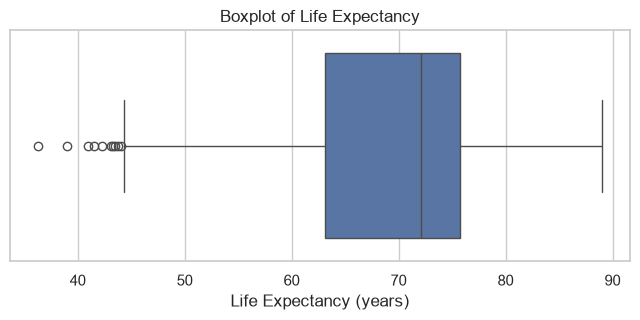

In [13]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["life_expectancy"])
plt.title("Boxplot of Life Expectancy")
plt.xlabel("Life Expectancy (years)")
plt.show()

### Step 6: Outlier Check
Outliers were identified using the IQR rule (values beyond 1.5 × IQR from the quartiles). The columns with the most outliers are **`measles`** (542 values, 18.5%), **`hiv_aids`** (542 values, 18.5%) and **`population`** (452 values, 15.4%), followed by `gdp` (443 values) and `under_five_deaths` (394 values). These columns are highly right-skewed: most countries have low values while a few have very large ones (for example very large populations or high HIV/AIDS and measles burdens). These values come from real countries rather than data-entry errors, so they were **kept** and not removed. Removing them would hide genuine differences between countries. Their effect will be taken into account when reading the scatter plots and correlations.

In [14]:
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/cleaned_life_expectancy.csv", index=False)
print("Saved:", df.shape)

Saved: (2928, 22)


### Step 7: Save the Cleaned Dataset
The cleaned dataset was saved as a new file, `data/processed/cleaned_life_expectancy.csv`. The raw file `data/life_expectancy.csv` was not modified.

In [15]:
lines = [
    "# Cleaning Log",
    "",
    "## Overview",
    f"- Raw dataset: {len(df_raw)} rows x {df_raw.shape[1]} columns (`data/life_expectancy.csv`, left untouched)",
    f"- Cleaned dataset: {df.shape[0]} rows x {df.shape[1]} columns (`data/processed/cleaned_life_expectancy.csv`)",
    f"- Rows dropped: {n_dropped} | Exact duplicates removed: {n_duplicates} | Missing values left: {int(df.isnull().sum().sum())}",
    "",
    "## General changes",
    "- **Column names:** stripped spaces, lowercased and replaced special characters with underscores (e.g. `HIV/AIDS` -> `hiv_aids`) to avoid hidden-space errors.",
    "- **Country names:** removed extra spaces and replaced long official names with common short names (e.g. `Viet Nam` -> `Vietnam`). The number of countries stayed the same.",
    "- **Data types:** all numeric columns were already numeric; `year` was cast to integer.",
    f"- **Duplicates:** {n_duplicates} exact duplicate rows found.",
    "",
    "## Missing values, column by column",
]
for col in num_cols:
    if missing_before[col] == 0:
        continue
    pct = round(missing_before[col] / rows_before * 100, 2)
    if col == target:
        lines.append(f"- `{col}`: {missing_before[col]} missing ({pct}%) -> **rows dropped**, because it is the target variable and imputing it would bias the analysis.")
    else:
        lines.append(f"- `{col}`: {missing_before[col]} missing ({pct}%) -> {missing_after_drop[col]} values **imputed with the country-wise median** (overall median as fallback), because this indicator changes slowly within a country.")

lines += ["", "## Outliers",
          "Outliers were checked with the IQR rule and boxplots. They were **kept**, because they represent real countries (very large populations, very high or low GDP and mortality) and not errors. Columns with the most outliers:"]
for _, r in outlier_df.head(5).iterrows():
    lines.append(f"- `{r['column']}`: {r['outliers']} values ({r['percent']}%)")

with open("../cleaning_log.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))
print("cleaning_log.md created")

cleaning_log.md created


In [16]:
sns.set_theme(style="whitegrid")
key_cols = ["life_expectancy", "adult_mortality", "infant_deaths", "alcohol", "bmi",
            "hiv_aids", "gdp", "total_expenditure", "income_composition_of_resources", "schooling"]

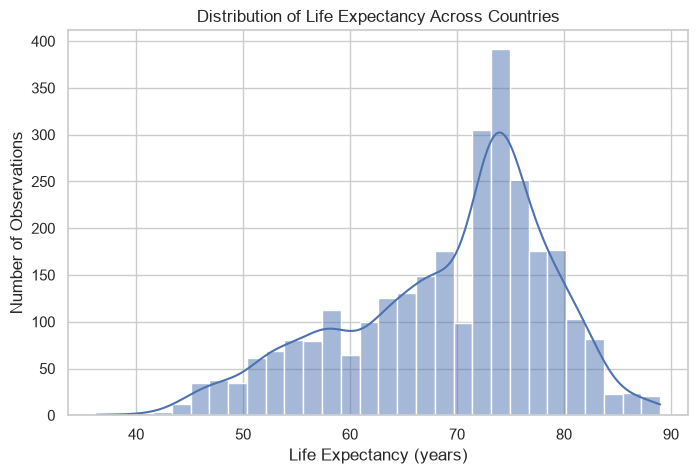

In [17]:
plt.figure(figsize=(8, 5))
sns.histplot(df["life_expectancy"], kde=True, bins=30)
plt.title("Distribution of Life Expectancy Across Countries")
plt.xlabel("Life Expectancy (years)")
plt.ylabel("Number of Observations")
plt.show()

**Chart 1: Distribution of life expectancy.** Most observations fall between about [lower] and [upper] years, with the highest concentration around [peak] years. The distribution is [skewed to the left / roughly symmetric], with a tail of countries that have very low life expectancy.

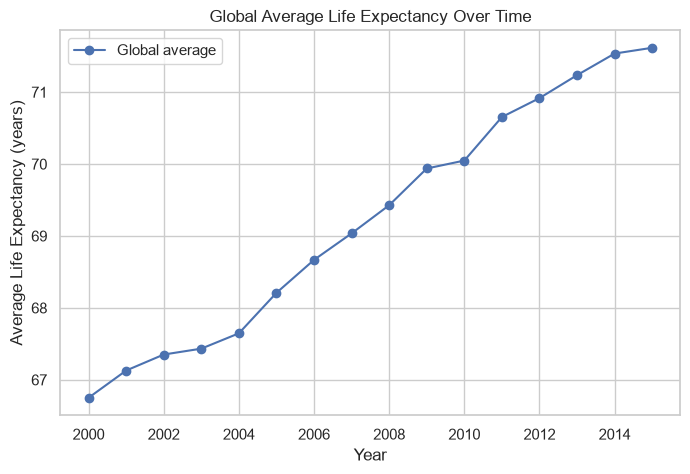

In [18]:
yearly = df.groupby("year")["life_expectancy"].mean()
plt.figure(figsize=(8, 5))
plt.plot(yearly.index, yearly.values, marker="o", label="Global average")
plt.title("Global Average Life Expectancy Over Time")
plt.xlabel("Year")
plt.ylabel("Average Life Expectancy (years)")
plt.legend()
plt.show()

**Chart 2: Global average life expectancy over time.** The average life expectancy across countries rose from about 66.8 years in 2000 to about 71.6 years in 2015, an increase of roughly 4.9 years. The upward trend shows steady improvement in health outcomes over the period.

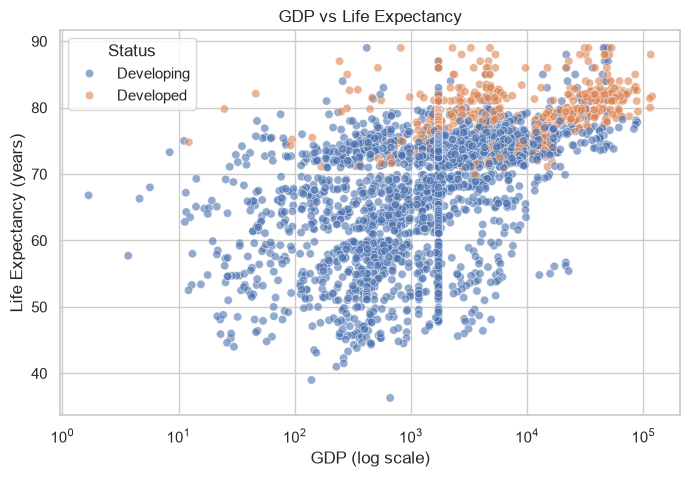

In [19]:
plot_df = df[df["gdp"] > 0]
plt.figure(figsize=(8, 5))
sns.scatterplot(data=plot_df, x="gdp", y="life_expectancy", hue="status", alpha=0.6)
plt.xscale("log")
plt.title("GDP vs Life Expectancy")
plt.xlabel("GDP (log scale)")
plt.ylabel("Life Expectancy (years)")
plt.legend(title="Status")
plt.show()

**Chart 3: GDP vs life expectancy.** Life expectancy tends to rise as GDP increases (correlation of about 0.43), and the pattern is easier to see on a log scale because GDP values are very spread out. Developed countries cluster at higher GDP and higher life expectancy, while developing countries show a wide range, so GDP alone does not fully explain differences in life expectancy.

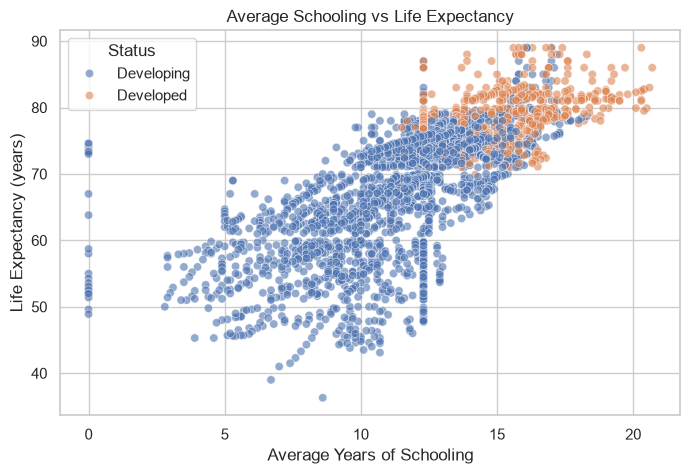

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="schooling", y="life_expectancy", hue="status", alpha=0.6)
plt.title("Average Schooling vs Life Expectancy")
plt.xlabel("Average Years of Schooling")
plt.ylabel("Life Expectancy (years)")
plt.legend(title="Status")
plt.show()

**Chart 4: Schooling vs life expectancy.** There is a strong positive relationship (correlation of about 0.72): countries with more years of schooling tend to have higher life expectancy. Developed countries sit in the upper right of the plot.

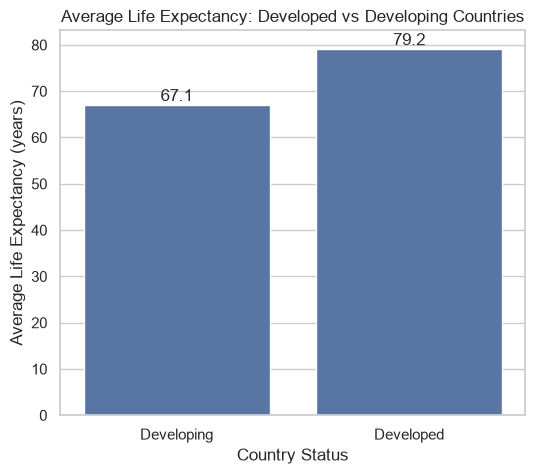

In [21]:
plt.figure(figsize=(6, 5))
ax = sns.barplot(data=df, x="status", y="life_expectancy", estimator="mean", errorbar=None)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f")
plt.title("Average Life Expectancy: Developed vs Developing Countries")
plt.xlabel("Country Status")
plt.ylabel("Average Life Expectancy (years)")
plt.show()

**Chart 5: Developed vs developing countries.** Developed countries have an average life expectancy of about 79.2 years compared with about 67.1 years for developing countries, a gap of roughly 12.1 years.

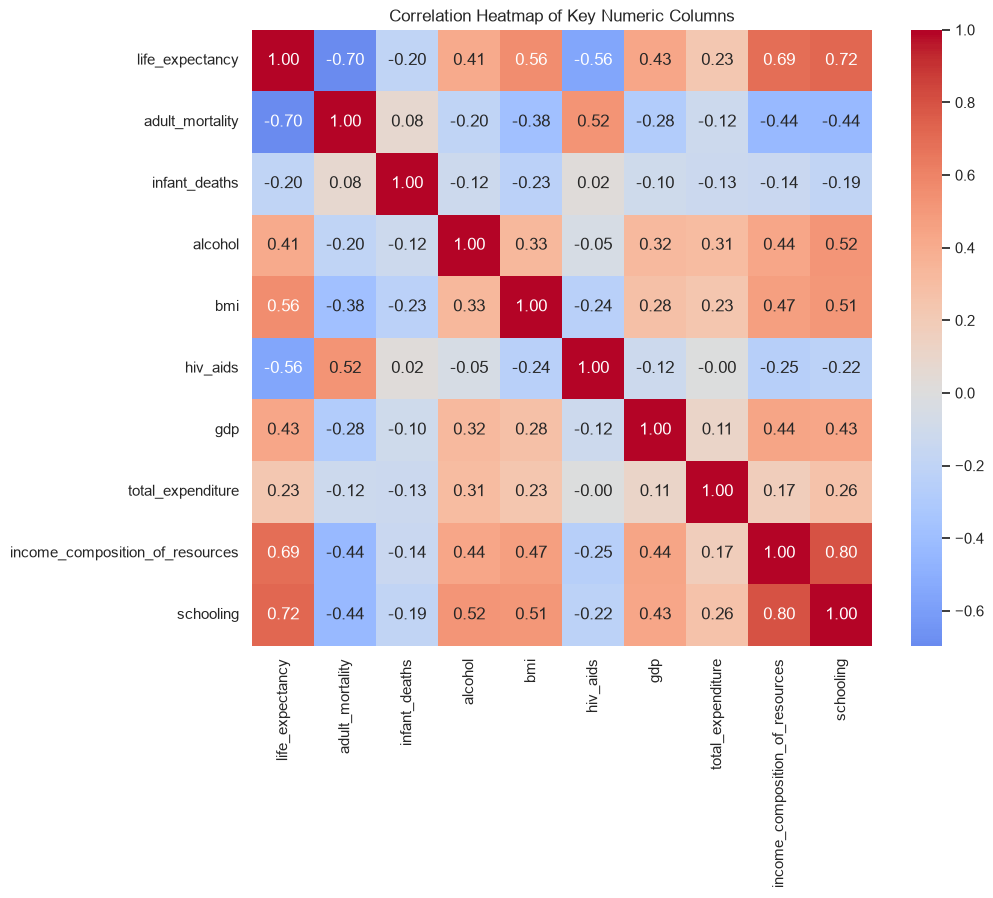

In [22]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[key_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Key Numeric Columns")
plt.show()

**Chart 6: Correlation heatmap.** Life expectancy is most strongly positively correlated with `schooling` (0.72) and `income_composition_of_resources` (0.69), followed by `bmi` (0.56) and `gdp` (0.43). It is most strongly negatively correlated with `adult_mortality` (-0.70) and `hiv_aids` (-0.56). Correlation does not prove causation: for example, the positive link with `alcohol` (0.41) most likely reflects that wealthier, more developed countries report higher values, not that alcohol raises life expectancy.

## Key Findings
1. **Life expectancy has improved over time.** The average across countries rose from about 66.8 years in 2000 to about 71.6 years in 2015, an increase of roughly 4.9 years.
2. **Development status matters.** Developed countries have an average life expectancy of about 79.2 years versus about 67.1 years for developing countries, a gap of roughly 12 years.
3. **Education and income-related factors are strongly linked to longevity.** `schooling` (0.72) and `income_composition_of_resources` (0.69) show the strongest positive correlations with life expectancy, while `gdp` shows a moderate one (0.43).
4. **Mortality and disease burden pull life expectancy down.** `adult_mortality` (-0.70) and `hiv_aids` (-0.56) have the strongest negative correlations.
5. **Correlation is not causation.** Some positive links, such as `alcohol` (0.41) and `bmi` (0.56), likely reflect that richer, developed countries differ on many indicators at once. These relationships should be examined more carefully in Week 3.
6. **Conclusion.** Life expectancy is shaped by a mix of economic, educational and health factors. The cleaned dataset is ready for deeper analysis in Week 3.